# Adaptive LTV for tokenized real estate: a fuzzy closed-loop controller

**Author:** Christophe Abelem — Inteligência Computacional, CESUPA, 2026

## Generative AI disclosure

<!-- TODO (Christophe): fill before delivery. The lauda requires at least the four items below. -->
- **Tool:**
- **Purpose:**
- **Approximate extent of the contribution:**
- **Validation measures:**

## How to run

1. `uv venv --python 3.12 && source .venv/bin/activate && uv pip install -r requirements.txt`
2. Run `00_data_test.ipynb` once (downloads and freezes the data in `data/`).
3. Run this notebook top to bottom.

## 1. Introduction and problem

**The setting.** Tokenized real estate splits a rental property into digital tokens. Each token gives its holder a
share of the rent. Holders can also deposit their tokens in a lending pool and borrow stablecoins (digital dollars)
against them, the way a home owner borrows against a house.

**The decision.** The pool must decide how much to lend per dollar of collateral. This ratio is the **maximum LTV**
(loan-to-value). With a max LTV of 60%, a token worth US$ 100 allows a loan of up to US$ 60. If the collateral loses
value and the loan rises above a second limit (the liquidation threshold), the position is **liquidated**: the
collateral is sold to repay the lenders. If the sale does not cover the debt, the shortfall is **bad debt**, a loss
for whoever lent the money.

**The problem.** A fixed max LTV ignores the state of the market. RealT, the largest tokenized real estate platform
(about 700 Detroit properties), used a fixed 60% in its lending market (RMM). In 2025-2026 rent stopped being
paid, the pool ran out of cash and liquidations surged; RealT announced its liquidation on 2 July 2026. Detroit house
prices, however, were near their all-time high. A rule that only watches prices would not have reacted.

**Objective.** Build a closed-loop fuzzy controller that sets the max LTV each month from three signals (price
volatility, pool liquidity, rent coverage) and compare its bad debt with the fixed 60% rule in two scenarios: a
market shock (prices fall, as in 2007-2011) and an operational collapse (rent and liquidity fail, as with RealT).

**Why fuzzy inference.** Risk teams set these limits with expert rules stated in words ("if volatility is high and
liquidity is low, lend less"). The boundaries are gradual, not sharp: 9% volatility is not "safe" while 9.1% is
"risky". Fuzzy sets model exactly this, and the rule base stays readable by someone outside finance.

**Sources and hypotheses.** Detroit prices: FRED `DEXRNSA`. Pool liquidity: DefiLlama. Risk parameters and
liquidations: read on-chain from the RMM contracts on Gnosis Chain. Rent coverage and appraisal steps are stylized
from documented dates (rent escrow Jul 2025, suspension Feb 2026), because no public time series exists. The data test
is in `00_data_test.ipynb`.

### Glossary

| Term | Meaning in this project |
| --- | --- |
| Collateral | The property tokens a borrower deposits to secure the loan |
| Max LTV | Largest loan allowed per dollar of collateral; the **output** of the controller |
| Liquidation threshold | Loan-to-value at which a position is liquidated (70% on RealT) |
| Liquidation | Forced sale of collateral to repay a loan that crossed the threshold |
| Bad debt | Debt left unpaid after a liquidation sale; the measure of failure |
| Volatility | How much prices swing; high volatility means collateral can lose value fast |
| Pool utilization | Share of the pool's cash already lent out; at 100% lenders cannot withdraw |
| Rent coverage | Share of expected rent actually paid; low coverage means the asset stopped producing income |
| Appraisal | Periodic official valuation of the property, used as the price the pool sees |

## Setup

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skfuzzy as fuzz

DATA = Path("data")
PROCESSED = DATA / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#9a9a9a",
    "axes.labelcolor": "#444444",
    "xtick.color": "#666666",
    "ytick.color": "#666666",
})
LINE = "#2a6fdb"
SHADE = "#d9d9d9"
TERM_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]   # low / medium / high (validated categorical slots 1-3)

## 2. Input variables

### 2.1 Market volatility (Detroit house prices)

The volatility input is computed from the S&P Cotality Case-Shiller MI-Detroit index (FRED `DEXRNSA`,
monthly, not seasonally adjusted). Three steps turn the index into a volatility the controller can use:

1. **Seasonal adjustment.** The index is not seasonally adjusted: prices rise every spring and fall every
   winter. Removing the average return of each calendar month keeps that pattern out of the volatility.
2. **De-smoothing.** A correction for appraisal-based indices, which react slowly: today's value
   carries part of last month's. Fit an AR(1) to the returns, then recover the underlying return with
   the Geltner formula below, where ρ is the AR(1) coefficient.
3. **Rolling volatility.** Standard deviation of the last 12 de-smoothed monthly returns, annualized by √12.

```latex
r^{true}_t = \frac{r^{obs}_t - \rho \, r^{obs}_{t-1}}{1 - \rho}
```

In [ ]:
cs = pd.read_csv(DATA / "cache" / "dexrnsa.csv", parse_dates=["date"], index_col="date")["dexrnsa"]

# 1. monthly log returns, seasonally adjusted (remove each calendar month's mean)
r_obs = np.log(cs).diff().dropna()
r_sa = r_obs - r_obs.groupby(r_obs.index.month).transform("mean") + r_obs.mean()

# 2. de-smoothing (Geltner): AR(1) coefficient, then recover the underlying return
rho = r_sa.autocorr(lag=1)
r_true = ((r_sa - rho * r_sa.shift(1)) / (1 - rho)).dropna()

# 3. 12-month rolling volatility, annualized
vol = (r_true.rolling(12).std() * np.sqrt(12)).dropna().rename("vol")

print(f"AR(1) rho = {rho:.3f}")
print(f"annualized vol, observed (SA): {r_sa.std() * np.sqrt(12):.1%}")
print(f"annualized vol, de-smoothed:   {r_true.std() * np.sqrt(12):.1%}")
print(f"rolling vol series: {vol.index.min():%Y-%m} to {vol.index.max():%Y-%m}, {len(vol)} months")

AR(1) rho = 0.725
annualized vol, observed (SA): 3.6%
annualized vol, de-smoothed:   9.1%
rolling vol series: 1992-02 to 2026-07, 414 months


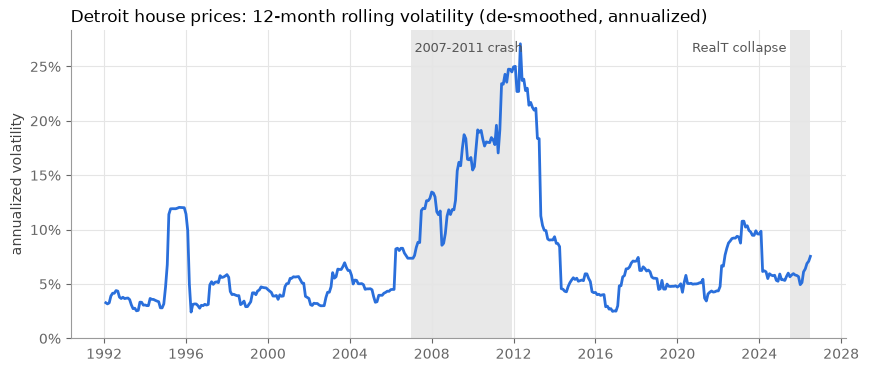

In [ ]:
fig, ax = plt.subplots()
for start, end in [("2007-01", "2011-12"), ("2025-07", "2026-07")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=SHADE, alpha=0.6, lw=0)
ax.plot(vol.index, vol, color=LINE, lw=2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.set_ylim(0, None)
ax.set_title("Detroit house prices: 12-month rolling volatility (de-smoothed, annualized)", loc="left")
ax.set_ylabel("annualized volatility")
ax.text(pd.Timestamp("2007-03"), ax.get_ylim()[1] * 0.93, "2007-2011 crash", color="#555555", fontsize=9)
ax.text(pd.Timestamp("2025-05"), ax.get_ylim()[1] * 0.93, "RealT collapse", color="#555555", fontsize=9, ha="right")
plt.show()

In [ ]:
vol_pct = vol.quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).rename("vol")
summary = pd.DataFrame({
    "percentile": [f"p{int(q * 100)}" for q in vol_pct.index],
    "vol": vol_pct.map("{:.1%}".format).values,
})
print(summary.to_string(index=False))
print("\nRealT period:")
print(vol.loc["2025-06":].map("{:.1%}".format).to_string())

vol.to_csv(PROCESSED / "vol_monthly.csv")

percentile   vol
       p10  3.2%
       p25  4.2%
       p50  5.5%
       p75  9.1%
       p90 16.6%
       p95 20.1%

RealT period:
date
2025-06-01    6.0%
2025-07-01    5.7%
2025-08-01    5.8%
2025-09-01    6.0%
2025-10-01    5.8%
2025-11-01    5.8%
2025-12-01    5.7%
2026-01-01    4.9%
2026-02-01    5.1%
2026-03-01    6.1%
2026-04-01    6.4%
2026-05-01    6.9%
2026-06-01    7.1%
2026-07-01    7.5%


**Interpretation.**

- **De-smoothing matters.** Correcting for appraisal smoothing (AR(1) ρ = 0.73) raises annualized volatility from 3.6% to 9.1%. The raw index hides most of the risk.
- **The 2007-2011 crash dominates the series,** with a peak of 27%. The peak came in May 2012, about a year after prices bottomed in April 2011: a 12-month rolling window only rises once the large drops are inside it, so the signal lags the price move. For the controller, this means volatility may cut the LTV late in a market shock, which the simulation must test.
- **During the RealT collapse (Jul 2025 to Jul 2026) volatility stayed between 4.9% and 7.5%,** close to the historical median of 5.5%. Detroit prices gave no warning, so a controller driven only by price risk would not have reacted. This supports the operational-collapse side of the hypothesis: the signal has to come from rent and pool liquidity.

### 2.2 Volatility as a fuzzy variable

**Universe:** 0% to 30% annualized volatility (the historical maximum is 27%).
**Terms:** low, medium, high, as trapezoids. The breakpoints are the historical percentiles of the series above, so no
number is chosen by hand:

| Term | Breakpoints | Reading |
| --- | --- | --- |
| low | 0, 0, p25, p50 | fully low up to p25, no longer low at the median |
| medium | p25, p50, p75, p90 | fully medium between the median and p75 |
| high | p75, p90, 30%, 30% | starts at p75, fully high from p90 |

Adjacent terms cross so that the memberships always sum to 1: every volatility value is covered, with no gaps.

In [ ]:
VOL_UNIVERSE = np.round(np.arange(0, 0.3001, 0.001), 3)
p25, p50, p75, p90 = vol.quantile([0.25, 0.50, 0.75, 0.90]).round(3)

VOL_POINTS = {
    "low": [0.0, 0.0, p25, p50],
    "medium": [p25, p50, p75, p90],
    "high": [p75, p90, 0.30, 0.30],
}
VOL_MF = {term: fuzz.trapmf(VOL_UNIVERSE, pts) for term, pts in VOL_POINTS.items()}

coverage = sum(VOL_MF.values())
print("breakpoints:", {t: [f"{x:.1%}" for x in pts] for t, pts in VOL_POINTS.items()})
print(f"membership sum over the universe: min {coverage.min():.3f}, max {coverage.max():.3f}")

def vol_memberships(x):
    return {t: round(float(fuzz.interp_membership(VOL_UNIVERSE, mf, x)), 2) for t, mf in VOL_MF.items()}

for label, x in [("median", p50), ("RealT period, max", vol.loc["2025-07":].max()), ("2012 peak", vol.max())]:
    print(f"{label:>18} ({x:.1%}): {vol_memberships(x)}")

breakpoints: {'low': ['0.0%', '0.0%', '4.2%', '5.5%'], 'medium': ['4.2%', '5.5%', '9.1%', '16.6%'], 'high': ['9.1%', '16.6%', '30.0%', '30.0%']}
membership sum over the universe: min 1.000, max 1.000
            median (5.5%): {'low': 0.0, 'medium': 1.0, 'high': 0.0}
 RealT period, max (7.5%): {'low': 0.0, 'medium': 1.0, 'high': 0.0}
         2012 peak (27.1%): {'low': 0.0, 'medium': 0.0, 'high': 1.0}


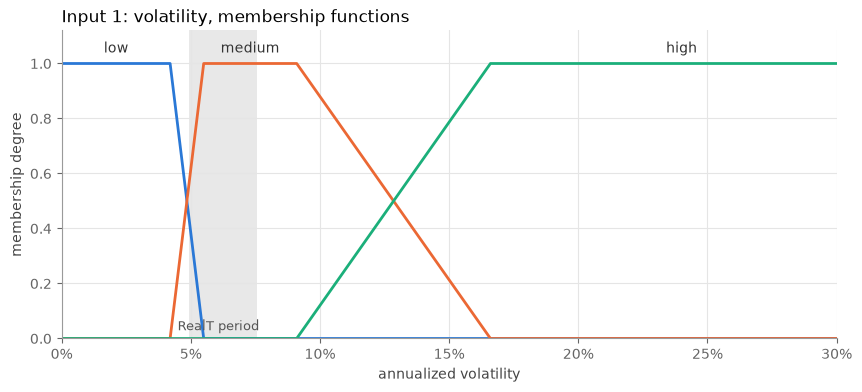

In [ ]:
fig, ax = plt.subplots()
ax.axvspan(vol.loc["2025-07":].min(), vol.loc["2025-07":].max(), color=SHADE, alpha=0.6, lw=0)
ax.text(vol.loc["2025-07":].mean(), 0.03, "RealT period", ha="center", color="#555555", fontsize=9)
for (term, mf), color in zip(VOL_MF.items(), TERM_COLORS):
    ax.plot(VOL_UNIVERSE, mf, color=color, lw=2)
    peak = VOL_UNIVERSE[mf == 1]
    ax.text(peak.mean() if term != "high" else 0.24, 1.04, term, color="#333333", fontsize=10, ha="center")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_ylim(0, 1.12)
ax.set_xlim(0, 0.30)
ax.set_xlabel("annualized volatility")
ax.set_ylabel("membership degree")
ax.set_title("Input 1: volatility, membership functions", loc="left")
plt.show()

**Reading.** The RealT period runs from 4.9% (about half "low", half "medium") to 7.5% (fully "medium"). The 2012 peak is fully
"high". Volatility alone would therefore keep the max LTV near its normal level during the RealT collapse.